# Lecture 5 examples: standard discrete distributions

We connect each distribution to its sampling mechanism, value set, and parameter convention. Model parameters and theoretical PMFs are fixed. Only the simulated observations are random; the approximation distances and tail errors are computed directly from the model laws. All simulations use the displayed random seed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

SEED = 20260811
rng = np.random.default_rng(SEED)
plt.style.use("seaborn-v0_8-whitegrid")

## 1. Distribution objects and parameter conventions

A geometric variable $G$ counts the trial of the first success, so its values start at $1$. SciPy follows this convention in `stats.geom(p)`. The successful trial is included in the count.

For a random variable $X$, `pmf(k)` returns $\mathbb P(X=k)$ and `cdf(k)` returns $F_X(k)=\mathbb P(X\le k)$. The survival-function call `sf(k)` returns $\mathbb P(X>k)$. Therefore, for any integer threshold $c$ and integer-valued $X$, use `sf(c-1)` to compute $\mathbb P(X\ge c)$.

For the Poisson object, SciPy's argument `mu` is the course parameter $\lambda$, the total intensity over the specified exposure. Under the arrival model, $\lambda=\rho t$ for a per-unit rate $\rho>0$ and exposure $t>0$. Independent counts on disjoint intervals, a stable rate, and negligible probability of multiple arrivals in a short interval motivate this law; an arbitrary count need not be Poisson.

The finite uniform example uses $A\coloneqq\{1,2,4,8\}$. Each value in $A$ has probability $1/4$, and all other values have probability zero.

In [3]:
p_success = 0.30
bernoulli = stats.bernoulli(p=p_success)
binomial = stats.binom(n=12, p=p_success)
geometric = stats.geom(p=p_success)
poisson = stats.poisson(mu=3.6)
uniform_support = np.array([1, 2, 4, 8])
uniform_mass = np.full(uniform_support.size, 1 / uniform_support.size)
discrete_uniform = stats.rv_discrete(
    name="finite_uniform", values=(uniform_support, uniform_mass)
)

print(f"Bernoulli P(X=1):             {bernoulli.pmf(1):.3f}")
print(f"Binomial P(X <= 3):           {binomial.cdf(3):.3f}")
print(f"Geometric P(G > 5):           {geometric.sf(5):.3f}")
print(f"Poisson P(X >= 5):            {poisson.sf(4):.3f}")
print(f"Discrete uniform P(X=8):      {discrete_uniform.pmf(8):.3f}")

assert np.isclose(geometric.pmf(1), p_success)

Bernoulli P(X=1):             0.300
Binomial P(X <= 3):           0.493
Geometric P(G > 5):           0.168
Poisson P(X >= 5):            0.294
Discrete uniform P(X=8):      0.250


## 2. PMF gallery

Each panel displays probability masses, not density values. The binomial panel shows every possible count. The geometric and Poisson laws have infinitely many possible values, so their panels show only finite ranges; probability outside those ranges is not renormalized away. Compare the stopping rule, parameters, and starting value of each law.

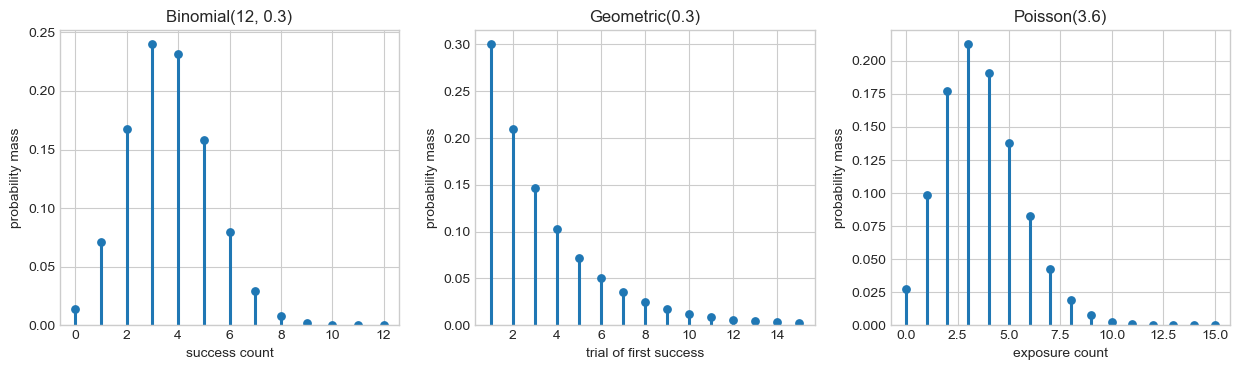

In [6]:
gallery = [
    (binomial, np.arange(0, 13), "Binomial(12, 0.3)", "success count"),
    (geometric, np.arange(1, 16), "Geometric(0.3)", "trial of first success"),
    (poisson, np.arange(0, 16), "Poisson(3.6)", "exposure count"),
]

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8))
for ax, (distribution, support, title, xlabel) in zip(axes.flat, gallery):
    masses = distribution.pmf(support)
    ax.vlines(support, 0, masses, color="tab:blue", linewidth=2.2)
    ax.scatter(support, masses, color="tab:blue", s=28)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("probability mass")
    ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

## 3. Geometric waiting-time simulation

We draw 30,000 independent observations from the geometric model, with success probability $p=0.3$. Each observation counts all trials up to and including the first success.

For each displayed value, the empirical relative frequency is the number of observations equal to that value divided by 30,000. We compare these random relative frequencies with the fixed theoretical probabilities; observations outside the plotted range remain part of the denominator.

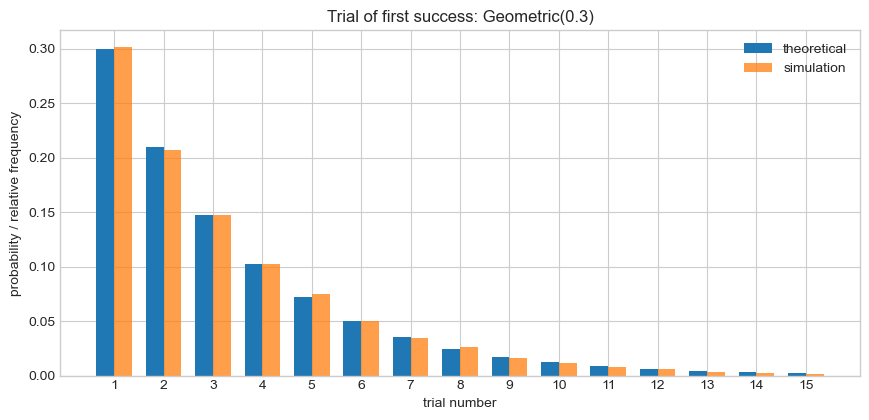

In [10]:
n_samples = 30_000
geometric_sample = geometric.rvs(size=n_samples, random_state=rng)
support = np.arange(1, 16)
empirical = np.array([(geometric_sample == value).mean() for value in support])

fig, ax = plt.subplots(figsize=(8.8, 4.3))
ax.bar(support - 0.18, geometric.pmf(support), width=0.36, label="theoretical")
ax.bar(support + 0.18, empirical, width=0.36, label="simulation", alpha=0.75)
ax.set_title("Trial of first success: Geometric(0.3)")
ax.set_xlabel("trial number")
ax.set_ylabel("probability / relative frequency")
ax.set_xticks(support)
ax.legend()
plt.tight_layout()
plt.show()

## 4. The opening device-alert calculation

Let $X$ count alerts when 1,000 devices are each checked once. Assume the alert events are mutually independent and each has probability $0.002$. Then $X\sim\operatorname{Binomial}(1000,0.002)$. Let $Y\sim\operatorname{Poisson}(2)$ be the approximating count, using $\lambda=np=2$.

We compute the exact-model probability $\mathbb P(X\ge5)$, the approximating probability $\mathbb P(Y\ge5)$, and their absolute difference. These are deterministic calculations from the two distributions, not Monte Carlo estimates.

In [13]:
n_devices = 1_000
alert_probability = 0.002
lambda_alerts = n_devices * alert_probability
alert_binomial = stats.binom(n=n_devices, p=alert_probability)
alert_poisson = stats.poisson(mu=lambda_alerts)

exact_tail = alert_binomial.sf(4)
poisson_tail = alert_poisson.sf(4)
print(f"exact P(X >= 5):       {exact_tail:.8f}")
print(f"Poisson approximation: {poisson_tail:.8f}")
print(f"absolute error:        {abs(exact_tail - poisson_tail):.8f}")

exact P(X >= 5):       0.05247239
Poisson approximation: 0.05265302
absolute error:        0.00018063


## 5. Poisson approximation with fixed $\lambda$

Hold $\lambda=2$ fixed. For each trial count $n\in\{20,100,1000\}$, set $p\coloneqq\lambda/n$ and compare the binomial PMF with the Poisson PMF on the displayed counts $0,\ldots,10$.

The binomial-to-Poisson theorem states convergence at each fixed count when $np_n\to\lambda$. It does not supply a finite-$n$ error bound, and a plot on a limited range does not compare the entire laws. We therefore compute complete-law distances in the next section.

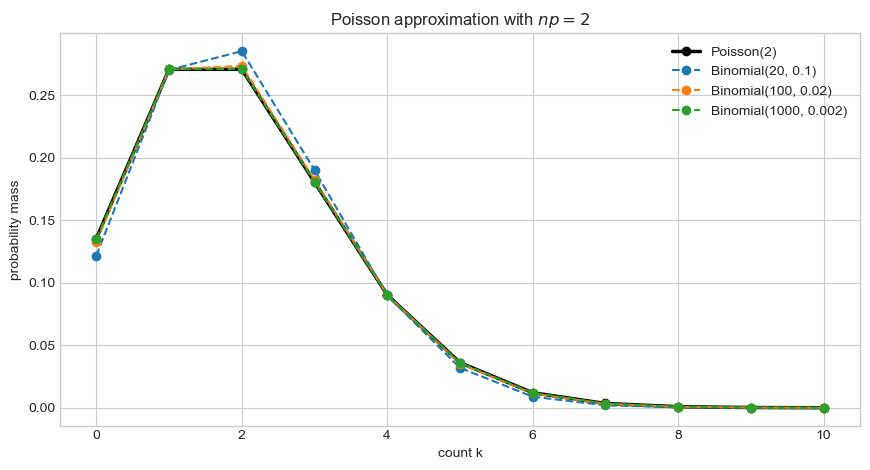

In [16]:
lambda_fixed = 2.0
support = np.arange(0, 11)
poisson_reference = stats.poisson(mu=lambda_fixed).pmf(support)
n_values = [20, 100, 1_000]

fig, ax = plt.subplots(figsize=(8.8, 4.8))
ax.plot(support, poisson_reference, color="black", marker="o", linewidth=2.5, label="Poisson(2)")
for n_trials in n_values:
    p_now = lambda_fixed / n_trials
    ax.plot(
        support,
        stats.binom(n=n_trials, p=p_now).pmf(support),
        marker="o",
        linestyle="--",
        label=f"Binomial({n_trials}, {p_now:.3g})",
    )
ax.set_xlabel("count k")
ax.set_ylabel("probability mass")
ax.set_title(r"Poisson approximation with $np=2$")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Comparing complete laws

Let $X,Y$ take values in $\mathbb N_0$, with PMFs $p_X,p_Y$. Define their **total-variation distance** by

$$
d_{\mathrm{TV}}(p_X,p_Y)\coloneqq\frac12\sum_{k=0}^{\infty}|p_X(k)-p_Y(k)|.\tag{1}
$$

For $n\in\mathbb N$ and $p\in(0,1]$, let $X\sim\operatorname{Binomial}(n,p)$ and $Y\sim\operatorname{Poisson}(np)$. Since $p_X(k)=0$ for every integer $k>n$, equation (1) becomes

$$
d_{\mathrm{TV}}(p_X,p_Y)
=\frac12\left[\sum_{k=0}^{n}|p_X(k)-p_Y(k)|+\mathbb P(Y>n)\right].\tag{2}
$$

The helper below implements equation (2), including the complete Poisson tail above $n$. The heat map evaluates this deterministic distance for each trial count $n$ and success probability $p$ on the displayed grids. Unlike Section 5, moving across a row holds $p$ fixed, so $\lambda=np$ changes. This heat map is not a fixed-$\lambda$ convergence experiment.

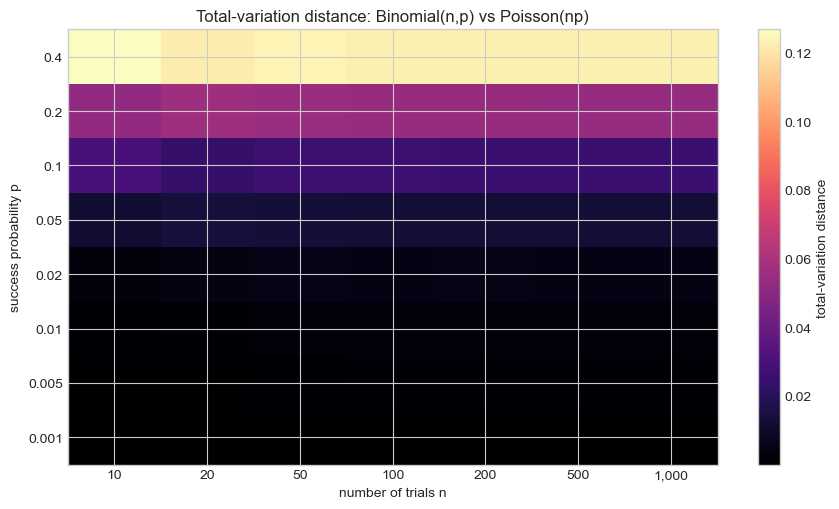

smallest distance on grid: 0.000010
largest distance on grid:  0.126726


In [19]:
def total_variation_binomial_poisson(n_trials, probability):
    lambda_ = n_trials * probability
    support = np.arange(0, n_trials + 1)
    point_difference = np.abs(
        stats.binom(n=n_trials, p=probability).pmf(support)
        - stats.poisson(mu=lambda_).pmf(support)
    ).sum()
    poisson_tail = stats.poisson(mu=lambda_).sf(n_trials)
    return 0.5 * (point_difference + poisson_tail)

n_grid = np.array([10, 20, 50, 100, 200, 500, 1_000])
p_grid = np.array([0.001, 0.005, 0.01, 0.02, 0.05, 0.10, 0.20, 0.40])
tv_grid = np.array([
    [total_variation_binomial_poisson(int(n_trials), probability) for n_trials in n_grid]
    for probability in p_grid
])

fig, ax = plt.subplots(figsize=(9, 5.2))
image = ax.imshow(tv_grid, aspect="auto", origin="lower", cmap="magma")
ax.set_xticks(range(len(n_grid)), labels=[f"{value:,}" for value in n_grid])
ax.set_yticks(range(len(p_grid)), labels=[f"{value:g}" for value in p_grid])
ax.set_xlabel("number of trials n")
ax.set_ylabel("success probability p")
ax.set_title("Total-variation distance: Binomial(n,p) vs Poisson(np)")
fig.colorbar(image, ax=ax, label="total-variation distance")
plt.tight_layout()
plt.show()

print(f"smallest distance on grid: {tv_grid.min():.6f}")
print(f"largest distance on grid:  {tv_grid.max():.6f}")

## Exercises

*Presentation format:* Prepare each solution as a short board presentation: define the objects and assumptions, show the intermediate argument or computation, and finish with a clear conclusion. For the Python/data task, bring your code and present the results by walking through the code and explaining the output.

1. **Conceptual.** For each scenario below, define the random variable, state its possible values, choose a law from this lecture, interpret every parameter, and list the assumptions that justify your choice.

    1. The class label of one image, chosen from a fixed finite set of classes.

    2. The number of defective items among $50$ manufactured items.

    3. The number of inspected items up to and including the first defective item.

    4. The number of website requests during a fixed ten-second interval.

    5. An integer selected uniformly from $\{1,\ldots,20\}$.
    Then choose two scenarios and change one modeling assumption in each. Explain why the original law is no longer justified, or identify a different law and justify its use.
    

2. **Mathematical.**

    1. Let $p\in(0,1)$ and $G\sim\operatorname{Geometric}(p)$. Derive $\mathbb P(G\ge k)$ for every $k\in\mathbb N$, and distinguish this event from $\{G>k\}$. Then prove

        $$

        \mathbb P(G>m+n\mid G>m)=\mathbb P(G>n)
        \qquad\text{for all }m,n\in\mathbb N_0,

        $$

        checking that the conditioning event has positive probability.

    2. Let $\lambda>0$ and $X\sim\operatorname{Poisson}(\lambda)$. Write $\mathbb P(X\ge3)$ as a complement, expand the required PMF terms, and simplify to a closed formula in $\lambda$.
    

3. **Python/data.** Use `lecture_05_examples.ipynb` as a starting point. For each fixed $\lambda\in\{1,5,10\}$ and each $n\in\{\lambda,2\lambda,5\lambda,10\lambda,50\lambda,100\lambda\}$, let

    $$

    X_n\sim\operatorname{Binomial}(n,\lambda/n),
    \qquad Y\sim\operatorname{Poisson}(\lambda).

    $$

    Here $p\coloneqq\lambda/n\in(0,1]$, and the case $n=\lambda$ is a binomial count with success probability one. Compare these fixed model laws; no Monte Carlo simulation is needed.

    1. Plot $d_{\mathrm{TV}}(p_{X_n},p_Y)$ against $n$, using one curve for each $\lambda$. Include the full Poisson probability above $n$, as in equation (2) in Section 6.

    2. For each $\lambda$, keep the integer threshold $c_\lambda\coloneqq2\lambda$ fixed while $n$ varies. Plot the absolute tail-probability error

        $$

        \bigl|\mathbb P(X_n\ge c_\lambda)-\mathbb P(Y\ge c_\lambda)\bigr|.

        $$

        Evaluate each distribution object's `sf` method at $c_\lambda-1$ to compute the probability of a count at least $c_\lambda$.

    3. Select one parameter pair $(\lambda,n)$ with a small total-variation distance and one with a larger distance. Display both PMFs for each pair, state the computed distances, and explain the contrast using $n$, $p=\lambda/n$, the possible count values, and the rare-event assumptions.